## Calculate the maximum energy needed for electron and protons

In [1]:
import os
import h5py
import numpy as np
import json

import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import flash_amr_tools

import astropy.units as u
import astropy.constants as const

Some general quantities that are the sameL:

In [2]:
vwind = 2.7e3 * u.km / u.s

Parameters and constants for cosmic rays

In [3]:
# energy parameters
mp = const.m_p.cgs
me = const.m_e.cgs
c = const.c.cgs
mu = 1.4  # mean molecular weight


def mom(e):
    """Normalised momentum as function of energy."""
    return np.sqrt((e + 1) ** 2 - 1)

def ekin(p):
    """Normalised kinetic energy as a function of normalised momentum"""
    return np.sqrt(p**2 + 1) - 1

def dp_dekin(p):
    """Derivative of normalised momentum wrt normalised kinetic energy."""
    return 2 * (ekin(p) + 1) / p

Acceleration timescale

In [4]:
def diff(p, diff_10GeV, mass=mp):
    return diff_10GeV * ((ekin(p) * mass * c**2 ).to(u.GeV) / (10 * u.GeV)).value**0.5

def t_accel(p, diff_10GeV, mass=mp):
    return 8 * diff(p, diff_10GeV, mass) / vwind**2

Escape paramneters

In [5]:
def standoff_radius(vstar):
    R0 = 1.02710 * u.pc if vstar == 40.0 * (u.km / u.s) else 0.42922 * u.pc
    return R0

def t_diff(p, vstar, diff_10GeV, mass=mp):
    R0 = standoff_radius(vstar)
    return R0**2 / diff(p, diff_10GeV, mass)

def t_adv(vstar):
    R0 = standoff_radius(vstar)
    return R0 / vstar

Cooling parameters

In [6]:

def b_hadr(p, rho):
    """Hadronic loss coefficient, depends on normalised momentum.

    Dimensionless as it is normalised by time scaling factor tau0."""
    # hadronic loss parameters
    sigma_pp = 44 * u.mbarn  # total pion cross section
    Kp = 0.5  # inelasticity
    B_hadr = (c * sigma_pp * Kp * rho / (mu * mp)).cgs  # hadronic loss coefficient
    # print(f"B_hadr = {B_hadr.cgs:.5e}")
    # invalid for momentum values < pion creation threshold
    return B_hadr * ekin(p) * dp_dekin(p)
    # return B_hadr


def b_coul(p, rho):
    """Coulomb loss coefficient, depends on normalised momentum.

    Dimensionless as it is normalised by time scaling factor tau0."""
    coul_coeff = -1e-18 * u.erg * u.cm**3 * u.s**-1
    n_e = 0.88 * rho / (mu * mp)
    B_coul = (coul_coeff * n_e / c / (mp * c)).cgs
    # print(f"B_coul = {B_coul.cgs:.5e}")
    return B_coul * (1 + p**-1.9)
    # return B_coul

def b_rad(p, B):
    """Loss coefficient for synchrotron & inverse compton effects. Only for electrons."""
    sigma_thom = 0.665 * u.barn  # thomson cross section (from NIST)
    u_phot = (0.5 * u.eV / u.cm**3).to(
        u.erg / u.cm**3
    )  # photon energy density from ISRF, Mathis 1983
    u_mag = (B**2 / (2 * const.mu0)).to(
        u.erg / u.cm**3
    )  # magnetic field energy density
    B_rad = (4 / 3 * sigma_thom * c * (u_mag + u_phot) / (me * c**2)).cgs
    # print(f"B_rad = {B_rad.cgs:.5e}")
    return B_rad * p**2 * dp_dekin(p)
    # return B_rad

def tcool_proton(p, rho):
    t_hadr = 1 / np.abs(b_hadr(p, rho))
    t_coul = 1 / np.abs(b_coul(p, rho))

    return (1 / t_hadr + 1 / t_coul)**-1 

def tcool_electron(p, rho, B):
    t_rad = 1 / np.abs(b_rad(p, B))
    t_coul = 1 / np.abs(b_coul(p, rho))

    return (1 / t_rad + 1 / t_coul)**-1 

#### Now calculate for vstar = 40km/s

In [7]:
ekin_arr = np.logspace(-6, 6, 500) * u.GeV

def mom_units(ekin, mass=mp):
    """Momentum in GeV/c"""
    return np.sqrt((ekin.cgs + mass*c**2)**2 - (mass*c**2)**2) / c

pp_arr = (mom_units(ekin_arr, mass=mp) / (mp * c)).to_value(u.dimensionless_unscaled)
pe_arr = (mom_units(ekin_arr, mass=me) / (me * c)).to_value(u.dimensionless_unscaled)


# take nominal values for the density and magnetic field at the shock
# this should be calcualted using the polar timeseries data and imported for each simulation type
# and take the mean value at the outer shock
rho_val = 4e-25 * u.g / u.cm**3
B_val = 10 * u.microgauss

vstar = 40 * u.km/u.s

diff_10GeV = 3e25 * u.cm**2 * u.s**-1

In [8]:
bowshock_config_dict = json.load(open("../../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

bs_names = ["ISM-v40-MDiff", "ISM-v40-LDiff", "ISM-v40-HDiff", "ISM-v100-MDiff"]

fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/revised/crshock"

<KeysViewHDF5 ['ISM-v100-MDiff', 'ISM-v40-HDiff', 'ISM-v40-LDiff', 'ISM-v40-MDiff']>
3.953742510193851e-25 g / cm3 9.162126066503578e-06 G
4.0008103337584293e-25 g / cm3 9.072330542310098e-06 G
2.687181883531809e-25 g / cm3 7.132382081734882e-06 G
4.306143174610732e-25 g / cm3 8.650106951886743e-06 G


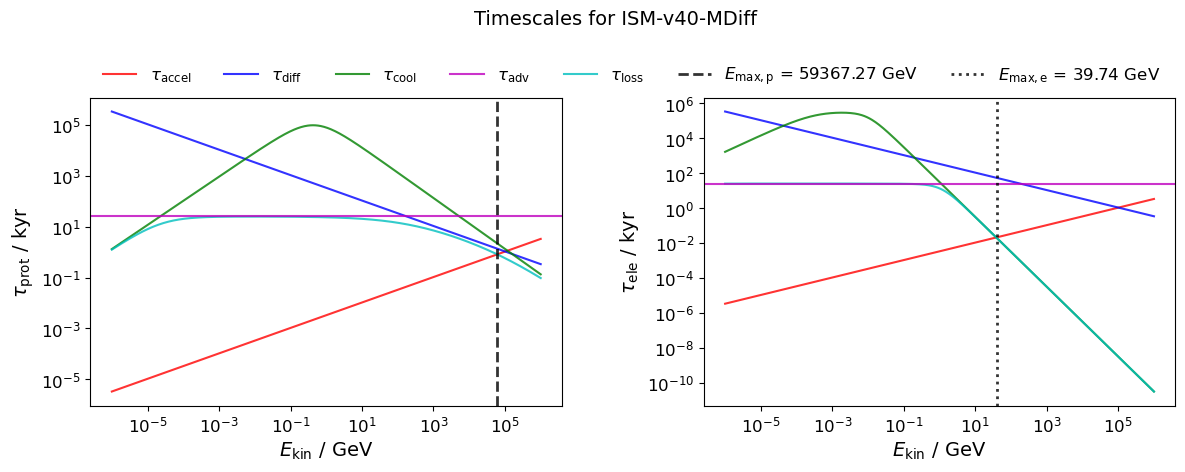

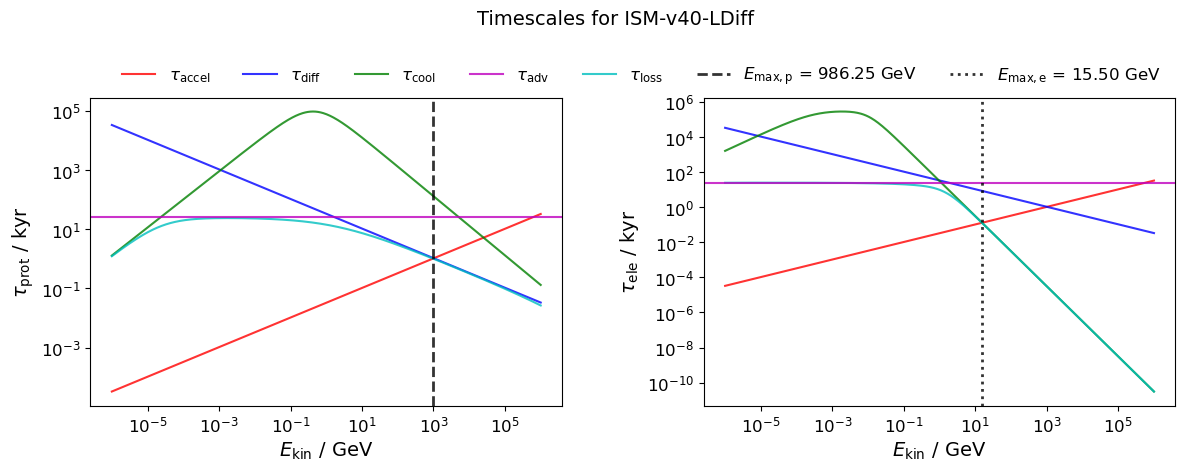

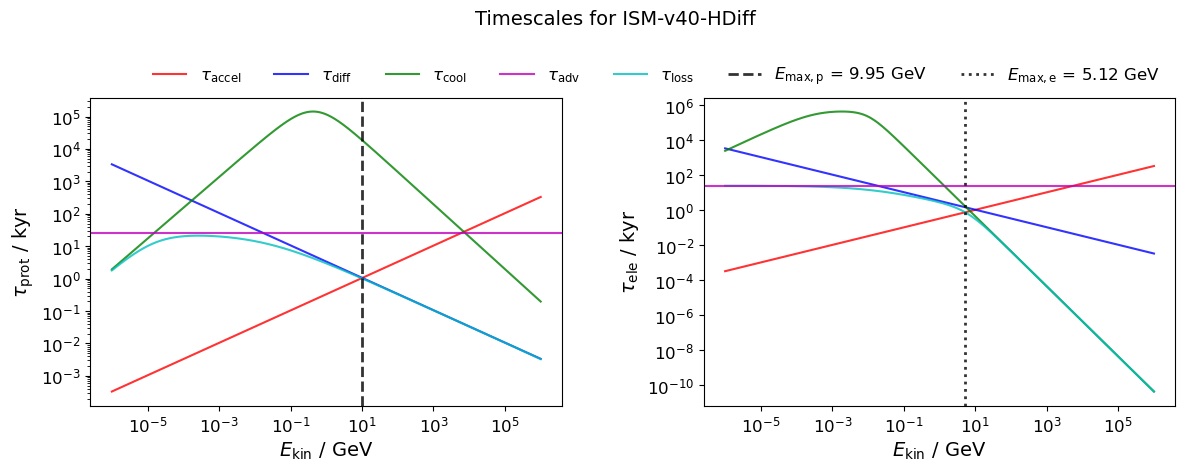

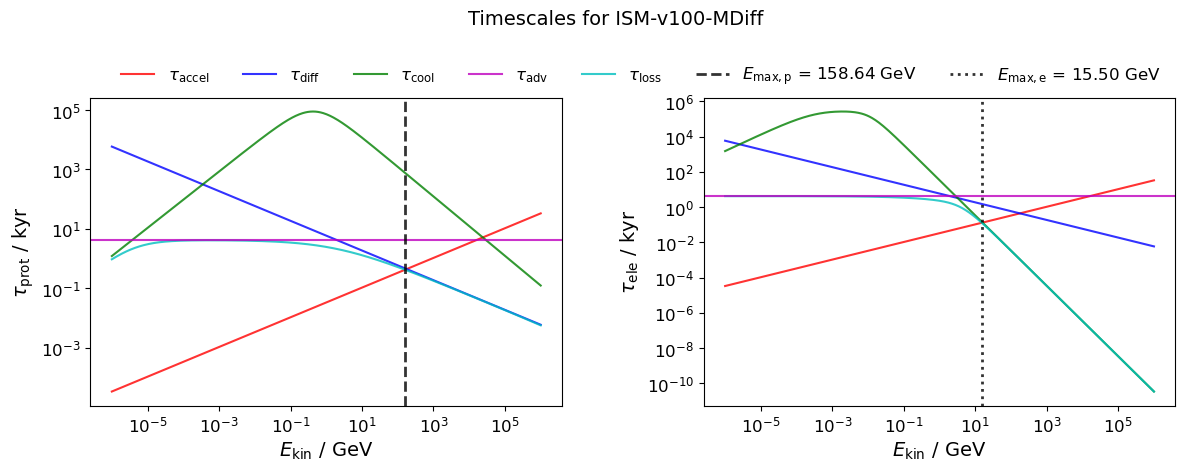

In [19]:
emax_prots = []
emax_electrs = []
file_to_read = f"../../data/polar_time_series_outer_revised.h5"
with h5py.File(file_to_read, "r") as f:

    print(f.keys())
    
    for ibs, bs_name in enumerate(bs_names):

        vstar = bowshock_config[bs_name]["vstar"] * u.km / u.s
        kappa_10 = bowshock_config[bs_name]["kappa_10"] * u.cm**2 / u.s

        dens_vals = f[bs_name]['dens'][()]
        mag_vals = f[bs_name]['mag'][()]
        rho_shock = np.mean(dens_vals[~np.isnan(dens_vals)]) * u.g / u.cm**3
        B_shock = np.mean(mag_vals[~np.isnan(mag_vals)]) * u.G
        print(rho_shock, B_shock)

        # claculate all times
        taccel_prot = t_accel(pp_arr, kappa_10, mass=mp).to(u.kyr)
        tdiff_prot = t_diff(pp_arr, vstar, kappa_10, mass=mp).to(u.kyr)
        tadv = t_adv(vstar).to(u.kyr)
        tcool_prot = tcool_proton(pp_arr, rho_shock).to(u.kyr)
        t_loss_prot = (1 / (1 / tcool_prot + 1 / tdiff_prot + 1 / tadv)).to(u.kyr)

        taccel_electr = t_accel(pe_arr, kappa_10, mass=me).to(u.kyr)
        tdiff_electr = t_diff(pe_arr, vstar, kappa_10, mass=me).to(u.kyr)
        tcool_electr = tcool_electron(pe_arr, rho_shock, B_shock).to(u.kyr)
        t_loss_electr = (1 / (1 / tcool_electr + 1 / tdiff_electr + 1 / tadv)).to(u.kyr)

        fig, axs = plt.subplots(1,2,figsize=(14,4), gridspec_kw={'wspace':0.3})

        axs[0].plot(ekin_arr, taccel_prot, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[0].plot(ekin_arr, tdiff_prot, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[0].plot(ekin_arr, tcool_prot, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[0].plot(ekin_arr, t_loss_prot, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[0].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[0].set_ylabel(r"$\tau_\mathrm{prot}$ / kyr", fontsize=14)
        
        axs[1].plot(ekin_arr, taccel_electr, label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8)
        axs[1].plot(ekin_arr, tdiff_electr, label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8)
        axs[1].plot(ekin_arr, tcool_electr, label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8)
        axs[1].plot(ekin_arr, t_loss_electr, label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8)
        axs[1].axhline(tadv.value, label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8)
        axs[1].set_ylabel(r"$\tau_\mathrm{ele}$ / kyr", fontsize=14)

        # finally find where taccel == tcool
        emax_prot = ekin_arr[np.argmin(np.abs(taccel_prot.value - t_loss_prot.value))]
        emax_electr = ekin_arr[np.argmin(np.abs(taccel_electr.value - t_loss_electr.value))]

        axs[0].axvline(emax_prot.value, label=rf'$E_\mathrm{{max}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0)
        axs[1].axvline(emax_electr.value, label=rf'$E_\mathrm{{max}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0)

        for ax in axs:
            ax.set_xlabel(r'$E_\mathrm{kin}$ / GeV', fontsize=14)
            ax.tick_params(axis='both', labelsize=12)
            ax.set_yscale('log')
            ax.set_xscale('log')

        
        fig.legend(
            handles=[
                mlines.Line2D([], [], label=r'$\tau_\mathrm{accel}$', color='r', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{diff}$', color='b', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{cool}$', color='g', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{adv}$', color='m', alpha=0.8),
                mlines.Line2D([], [], label=r'$\tau_\mathrm{loss}$', color='c', alpha=0.8),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, p}}$ = {emax_prot.to(u.GeV):.2f}', color='k', alpha=0.8, ls="--", lw=2.0),
                mlines.Line2D([], [], label=rf'$E_\mathrm{{max, e}}$ = {emax_electr:.2f}', color='k', alpha=0.8, ls=":", lw=2.0),
            ],
            fontsize=12,
            ncols=7,
            frameon=False,
            bbox_to_anchor=[0.9, 1.0]
        )

        fig.suptitle(f"Timescales for {bs_name}", fontsize=14, y=1.1)
        
        # emax_prot = ekin_arr[np.argwhere(np.isclose(taccel_prot.value, tcool_prot.value))]
        # print(emax_prot)

        emax_prots.append(emax_prot.to_value(u.GeV))
        emax_electrs.append(emax_electr.to_value(u.GeV))

emax_electrs = np.array(emax_electrs)
emax_prots = np.array(emax_prots)


In [30]:
print("emax_prots =", emax_prots, " GeV")
print("emax_electrs =", emax_electrs, " GeV")

emax_prots = [5.93672722e+04 9.86252179e+02 9.95396231e+00 1.58635653e+02]  GeV
emax_electrs = [39.73730381 15.50175117  5.12175544 15.50175117]  GeV


In [31]:
pmax_prot = mom(emax_prots / (mp * c**2).to_value(u.GeV))
pmax_electr = mom(emax_electrs / (me * c**2).to_value(u.GeV))

print("pmax_prot =", pmax_prot, " / (mpc)")
print("pmax_electr =", pmax_electr, " / (mec)")

pmax_prot = [6.32739812e+04 1.05213617e+03 1.15656719e+01 1.70069182e+02]  / (mpc)
pmax_electr = [77764.96372609 30337.17028969 10024.02532699 30337.17028969]  / (mec)
